# 01 · EDA → feature engineering → leak-free pipeline → saved model

**Goal:** the full classic-ML workflow an ML engineer is expected to run end to end, on clinical-style tabular data.
**Time:** ~3 hours.

**Data:** put the Kaggle *Heart Failure Prediction* file at `../data/heart.csv`
(https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction). If it is missing, the notebook
generates a synthetic dataset with the same columns so everything still runs.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, classification_report

SEED = 42

In [2]:
def synthetic_heart(n=918, seed=SEED):
    r = np.random.default_rng(seed)
    df = pd.DataFrame({
        "Age": r.integers(28, 78, n),
        "Sex": r.choice(["M", "F"], n, p=[0.79, 0.21]),
        "ChestPainType": r.choice(["ASY", "NAP", "ATA", "TA"], n, p=[0.54, 0.22, 0.19, 0.05]),
        "RestingBP": r.normal(132, 18, n).round(),
        "Cholesterol": r.normal(240, 55, n).round(),
        "FastingBS": (r.random(n) < 0.23).astype(int),
        "RestingECG": r.choice(["Normal", "LVH", "ST"], n, p=[0.6, 0.2, 0.2]),
        "MaxHR": r.normal(137, 25, n).round(),
        "ExerciseAngina": r.choice(["N", "Y"], n, p=[0.6, 0.4]),
        "Oldpeak": np.clip(r.normal(0.9, 1.0, n), 0, 6).round(1),
        "ST_Slope": r.choice(["Flat", "Up", "Down"], n, p=[0.5, 0.43, 0.07]),
    })
    df.loc[r.random(n) < 0.19, "Cholesterol"] = 0          # like the real file: 0 = not measured
    logit = (0.04 * (df.Age - 54) + 0.9 * (df.Sex == "M") + 1.3 * (df.ChestPainType == "ASY")
             + 1.0 * (df.ExerciseAngina == "Y") + 0.5 * df.Oldpeak + 1.4 * (df.ST_Slope == "Flat")
             - 0.015 * (df.MaxHR - 137) + 0.6 * df.FastingBS - 2.2)
    df["HeartDisease"] = (r.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return df

path = Path("../data/heart.csv")
df = pd.read_csv(path) if path.exists() else synthetic_heart()
print("source:", "real heart.csv" if path.exists() else "SYNTHETIC (add ../data/heart.csv for real results)")
df.head()

source: SYNTHETIC (add ../data/heart.csv for real results)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,32,M,ATA,121.0,0.0,0,Normal,138.0,N,0.4,Flat,0
1,66,M,NAP,104.0,0.0,0,LVH,105.0,N,0.0,Up,0
2,60,M,ASY,119.0,259.0,0,LVH,165.0,N,1.6,Up,1
3,49,F,ASY,131.0,0.0,0,ST,124.0,N,1.7,Up,1
4,49,M,ASY,153.0,0.0,1,ST,121.0,N,1.8,Up,1


## 1. EDA: understand before you model
Checklist: shape, types, missing values, impossible values, target balance, distributions,
relationship of each feature with the target, correlations.

In [3]:
print(df.shape)
print(df.dtypes.value_counts())
print("\nmissing per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("\ntarget balance:\n", df.HeartDisease.value_counts(normalize=True).round(3))
df.describe().T.round(1)

(918, 12)
object     5
float64    4
int64      3
Name: count, dtype: int64

missing per column:
 Series([], dtype: int64)

target balance:
 HeartDisease
1    0.654
0    0.346
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Age,918.0,52.7,14.6,28.0,40.0,53.0,66.0,77.0
RestingBP,918.0,133.0,18.5,77.0,120.2,133.0,146.0,187.0
Cholesterol,918.0,191.7,107.5,0.0,159.0,223.0,266.8,410.0
FastingBS,918.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0
MaxHR,918.0,137.8,25.8,62.0,121.0,136.0,156.0,217.0
Oldpeak,918.0,1.0,0.8,0.0,0.2,0.9,1.5,4.9
HeartDisease,918.0,0.7,0.5,0.0,0.0,1.0,1.0,1.0


In [4]:
# impossible values hide as zeros
print("Cholesterol == 0:", (df.Cholesterol == 0).sum(), "rows")
print("RestingBP == 0:", (df.RestingBP == 0).sum(), "rows")

Cholesterol == 0: 184 rows
RestingBP == 0: 0 rows


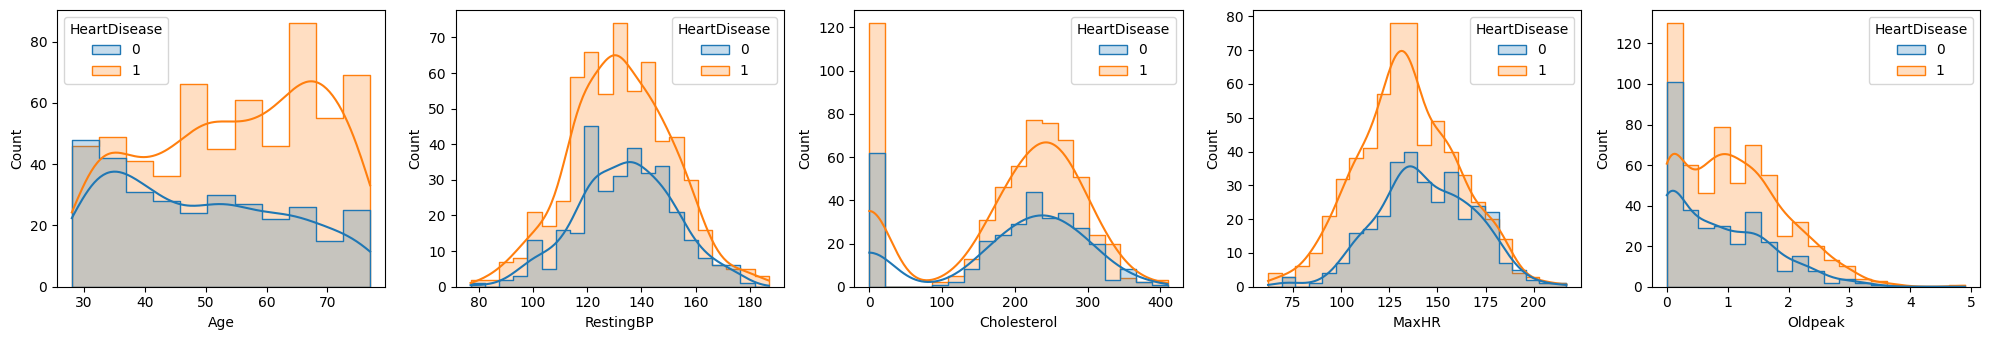

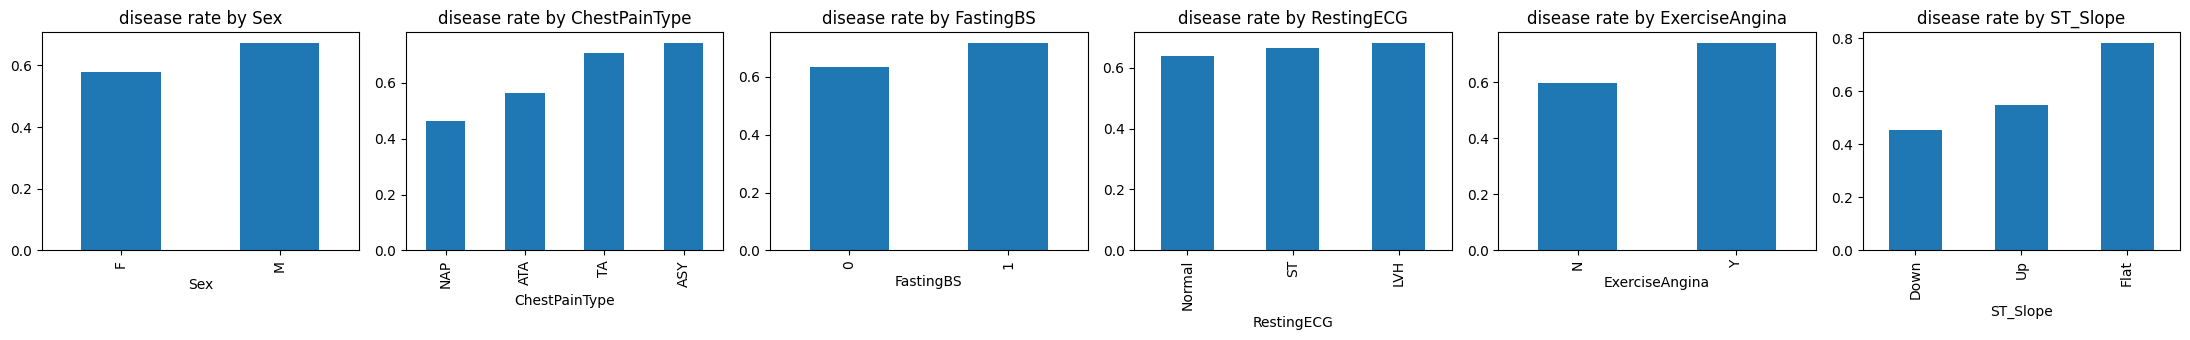

In [5]:
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
cat_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=df, x=c, hue="HeartDisease", kde=True, ax=ax, element="step")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 6, figsize=(22, 3.5))
for ax, c in zip(axes, cat_cols):
    df.groupby(c).HeartDisease.mean().sort_values().plot.bar(ax=ax, title=f"disease rate by {c}")
plt.tight_layout(); plt.show()

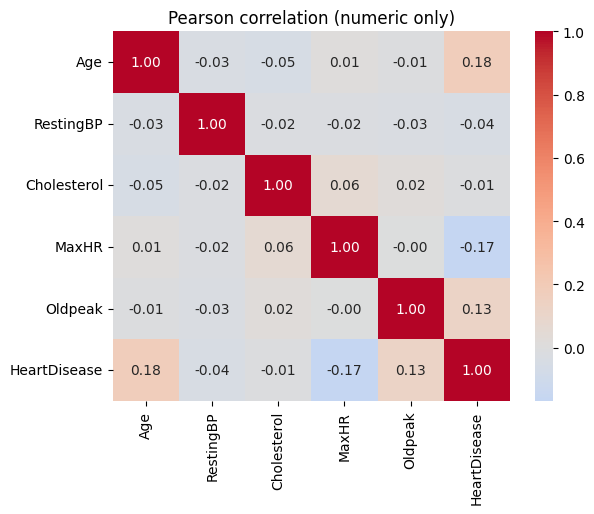

In [6]:
sns.heatmap(df[num_cols + ["HeartDisease"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson correlation (numeric only)"); plt.show()

## 2. Split FIRST, then engineer features inside the pipeline
Feature ideas (all computed per row, so no leakage risk, but we still keep them in the pipeline so the
same code runs in production):
- `Cholesterol == 0` → missing value + a "was missing" indicator.
- Age bands (domain knowledge; lets a linear model bend).
- `HR_reserve` ≈ 220 − Age − MaxHR (how far below the age-predicted max the patient reached).

In [7]:
X = df.drop(columns="HeartDisease"); y = df.HeartDisease
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

def add_features(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["Cholesterol"] = d["Cholesterol"].replace(0, np.nan)
    d["RestingBP"] = d["RestingBP"].replace(0, np.nan)
    d["AgeBand"] = pd.cut(d["Age"], [0, 40, 55, 70, 120], labels=["<40", "40-54", "55-69", "70+"]).astype(str)
    d["HR_reserve"] = 220 - d["Age"] - d["MaxHR"]
    d["FastingBS"] = d["FastingBS"].astype(str)
    return d

num = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak", "HR_reserve"]
cat = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope", "AgeBand"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat),
])

def make_pipe(model):
    return Pipeline([("features", FunctionTransformer(add_features)),
                     ("prep", preprocess), ("model", model)])

## 3. Compare models with stratified 10-fold CV (mean ± std, train vs validation)

In [8]:
cv = StratifiedKFold(10, shuffle=True, random_state=SEED)
candidates = {
    "LogReg": LogisticRegression(max_iter=2000),
    "HistGB": HistGradientBoostingClassifier(random_state=SEED),
}
rows = []
for name, m in candidates.items():
    r = cross_validate(make_pipe(m), X_train, y_train, cv=cv, scoring=["roc_auc", "accuracy"], return_train_score=True)
    rows.append({"model": name,
                 "val AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                 "train AUC": f"{r['train_roc_auc'].mean():.3f}",
                 "val acc": f"{r['test_accuracy'].mean():.3f}"})
pd.DataFrame(rows)

,model,val AUC,train AUC,val acc
0,LogReg,0.782 ± 0.068,0.805,0.733
1,HistGB,0.749 ± 0.064,1.000,0.710


A large train–validation gap (often for boosting) = overfitting → tune regularisation.

## 4. Tune with GridSearchCV (still only on the training set)

In [9]:
search = GridSearchCV(
    make_pipe(HistGradientBoostingClassifier(random_state=SEED)),
    {"model__max_depth": [2, 3, None], "model__learning_rate": [0.03, 0.1],
     "model__min_samples_leaf": [20, 50], "model__l2_regularization": [0.0, 1.0]},
    cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X_train, y_train)
print("best params:", search.best_params_, "| CV AUC:", round(search.best_score_, 3))

lr_search = GridSearchCV(make_pipe(LogisticRegression(max_iter=2000)),
                         {"model__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="roc_auc")
lr_search.fit(X_train, y_train)
print("LogReg best C:", lr_search.best_params_, "| CV AUC:", round(lr_search.best_score_, 3))

best params: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.03, 'model__max_depth': None, 'model__min_samples_leaf': 50} | CV AUC: 0.774


LogReg best C: {'model__C': 1} | CV AUC: 0.782


## 5. One final look at the test set

In [10]:
final = lr_search.best_estimator_ if lr_search.best_score_ >= search.best_score_ else search.best_estimator_
p = final.predict_proba(X_test)[:, 1]
print("chosen:", type(final.named_steps["model"]).__name__)
print("TEST ROC-AUC:", round(roc_auc_score(y_test, p), 3))
print(classification_report(y_test, (p >= 0.5).astype(int), digits=3))

chosen: LogisticRegression
TEST ROC-AUC: 0.819
              precision    recall  f1-score   support

           0      0.755     0.578     0.655        64
           1      0.800     0.900     0.847       120

    accuracy                          0.788       184
   macro avg      0.778     0.739     0.751       184
weighted avg      0.784     0.788     0.780       184



## 6. Interpret: odds ratios from logistic regression
A coefficient `w` on a standardised feature means: +1 std → odds × `exp(w)`.

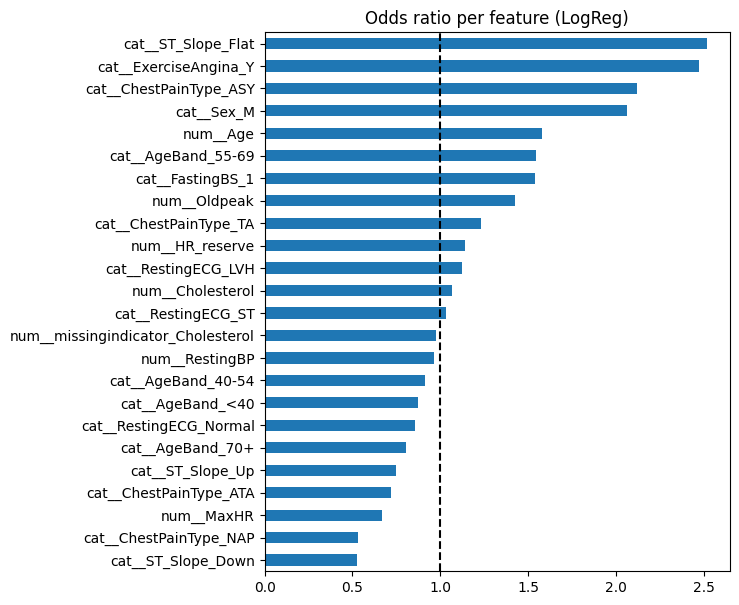

In [11]:
lr = lr_search.best_estimator_
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names)
odds = np.exp(coefs).sort_values()
odds.plot.barh(figsize=(6, 7), title="Odds ratio per feature (LogReg)"); plt.axvline(1, color="k", ls="--"); plt.show()

## 7. Save and use the model like an API would
The whole pipeline (feature code + preprocessing + model) is one object, so serving code can't drift
from training code.

In [12]:
Path("artifacts").mkdir(exist_ok=True)
joblib.dump(final, "artifacts/heart_model.joblib")

loaded = joblib.load("artifacts/heart_model.joblib")
new_patient = pd.DataFrame([{"Age": 61, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140, "Cholesterol": 0,
                             "FastingBS": 1, "RestingECG": "Normal", "MaxHR": 110, "ExerciseAngina": "Y",
                             "Oldpeak": 2.0, "ST_Slope": "Flat"}])
print("risk:", round(loaded.predict_proba(new_patient)[0, 1], 3))

risk: 0.989


## ✍️ Your turn
1. Download the real `heart.csv`, rerun everything, and copy the results table into the README of your
   `Heart-Disease-Analysis-and-prediction` repo.
2. Wrap `loaded.predict_proba` in a FastAPI endpoint `POST /predict` (see module 09).
3. Add one new engineered feature. Did CV AUC improve by more than one std? If not, it's noise.

## 🎯 Interview check
- Walk me through how you'd build a model for a new tabular dataset, from raw file to API.
- Why put `add_features` and the imputer inside the pipeline?
- How do you handle unseen categories at prediction time?
- Mean vs median imputation, and when to add a missing-indicator.

In [13]:
# Your code here